# Launching Satellites w/ Quadratic Air Drag: 
A handful of startup companies are looking to revolutionize the space industry by launching satellites from the ground with a huge initial velocity, which will take them to a specified height in the atmosphere before using any sort of rocket propulsion to carry the craft the rest of the way into orbit (see SpinLaunch as an example of this idea in action- https://www.spinlaunch.com/). This method of launching satellites effectively removes the ‘first stage’ of a rocket, which is a majority of the weight and fuel cost in a traditional rocket launch (think about the discussion we just had in Chp 3). If successful, this is will be a huge achievement, but many technical barriers remain before the idea can be fully realized. Imagine now for a moment, that you are part of a team working to develop a space launch system under this paradigm. You are being tasked with estimating the initial velocity of launch needed to achieve a height of 80 km above earth’s surface including realistic effects such as air drag.
Computational Methods: For this problem, I am asking you to use a different approach compared to problem #2, because that solution makes a few assumptions that we’ll want to avoid for a problem of this nature. Instead, let’s model the drag force in exercise using an equation known as the Prandtl expression, which is given by $F(v) = \frac{1}{2}c_w\rho_{air}Av^2$ , where $c_w$ is known as the drag coefficient, $\rho_{air}$ is the density of air, $A$ is the cross-section of the object, and $v$ is the velocity. What
makes this calculation tricky is that the density of air decreases with height in the atmosphere (as
in problem 2, but you will likely want to reference a detailed model of the atmosphere such as
NRLMSISE-00, which is available here: https://www.amentum.io/atmosphere_docs#tag/wam or see https://en.wikipedia.org/wiki/NRLMSISE-00) and also the drag coefficient depends on speed (and example plot is given below showing dependence of Mach number which is the ratio of speed vs. sound speed in medium). These additional dependencies on position and velocity go beyond the simple form $F(v) ∝ v^2$ and make the problem much more tractable using numerical methods. My advice for this exercise is to think about solving the equation using a grid of points (or regions) through the atmosphere and solving the equation where we can assume simple functional forms for $c_w$ and $\rho_{air}$ , and then if needed ‘stitching’ the answers together using common boundary conditions to link one region to the next for where the functional forms of these equations might have changed from one region to the next. Note this approach will require you to think very carefully about boundary conditions and ensuring your solution doesn’t violate assumptions you make about the drag coefficient and air density profile. You will also likely have to produce several trials of this calculation to determine the height achieved, and then do some iterations based on your initial velocity ‘guesses’ to figure out the velocity value corresponding to the desired height in the atmosphere. I’ll note that I don’t consider there to be a ‘correct’ answer to this problem, because I want to give you the freedom to think about the problem with an open mind. You are able to make choices and assumptions in this problem that make the numerics more approachable. But I will say that the better your choices and assumptions are, the more accurate your solution will be. That said, part of the grading will ask you to critically evaluate how ‘reasonable’ some of your choices are. If you have questions or concerns about specific items in this regard, please feel free to ask me.

Since we're talking about a fast-moving, massive object like a rocket, we are definitely in the  regime where 

$$
R_e = \frac{f_{quad}}{f_{lin}} = \frac{\rho_{air}Dv}{\eta} >> 1000
$$

So the quadratic drag dominates. Let's launch the rocket straight up, since that will give us the greatest vertical range. Then the equation of motion is 

$$
ma = F_y = -F(v) - mg \\
\dot{v} = -\frac{1}{2m}c_w\rho_{air}Av^2 -g
$$

For my calculations, I'll be using the mold of Firefly's Alpha rocket, a small 

In [28]:
import requests
from html_table_parser import HTMLTableParser
import pandas as pd

url = "https://www.engineeringtoolbox.com/standard-atmosphere-d_604.html"
response = requests.get(url)
xhtml = response.text

p = HTMLTableParser()
p.feed(xhtml)
# pprint(p.tables[1]) 

# Turn into a pandas dataframe and simplify column names
df = pd.DataFrame(p.tables[1][1:], columns=p.tables[1][0])
new_columns = ['Altitude (m)', 'Temperature (°C)', 'g (m/s²)', 'Pressure (10⁴ Pa)', 'Density (kg/m³)', 'Viscocity (10^-5 N*s/m²)']
df = df.rename(columns=dict(zip(df.columns, new_columns)))

# Convert columns to floats
for col in df.columns:
    df[col] = df[col].astype(float)

# Convert temp to Kelvin
df['Temperature (°C)'] = df['Temperature (°C)'] + 273.15
df = df.rename(columns={'Temperature (°C)': 'Temperature (K)'})

print(df)
df.to_csv('atmosphere_data.csv', index=False)

    Altitude (m)  Temperature (K)  g (m/s²)  Pressure (10⁴ Pa)  \
0        -1000.0           294.65     9.810          11.390000   
1            0.0           288.15     9.807          10.130000   
2         1000.0           281.65     9.804           8.988000   
3         2000.0           275.15     9.801           7.950000   
4         3000.0           268.66     9.797           7.012000   
5         4000.0           262.17     9.794           6.166000   
6         5000.0           255.68     9.791           5.405000   
7         6000.0           249.19     9.788           4.722000   
8         7000.0           242.70     9.785           4.111000   
9         8000.0           236.21     9.782           3.565000   
10        9000.0           229.73     9.779           3.080000   
11       10000.0           223.25     9.776           2.650000   
12       15000.0           216.65     9.761           1.211000   
13       20000.0           216.65     9.745           0.552900   
14       2

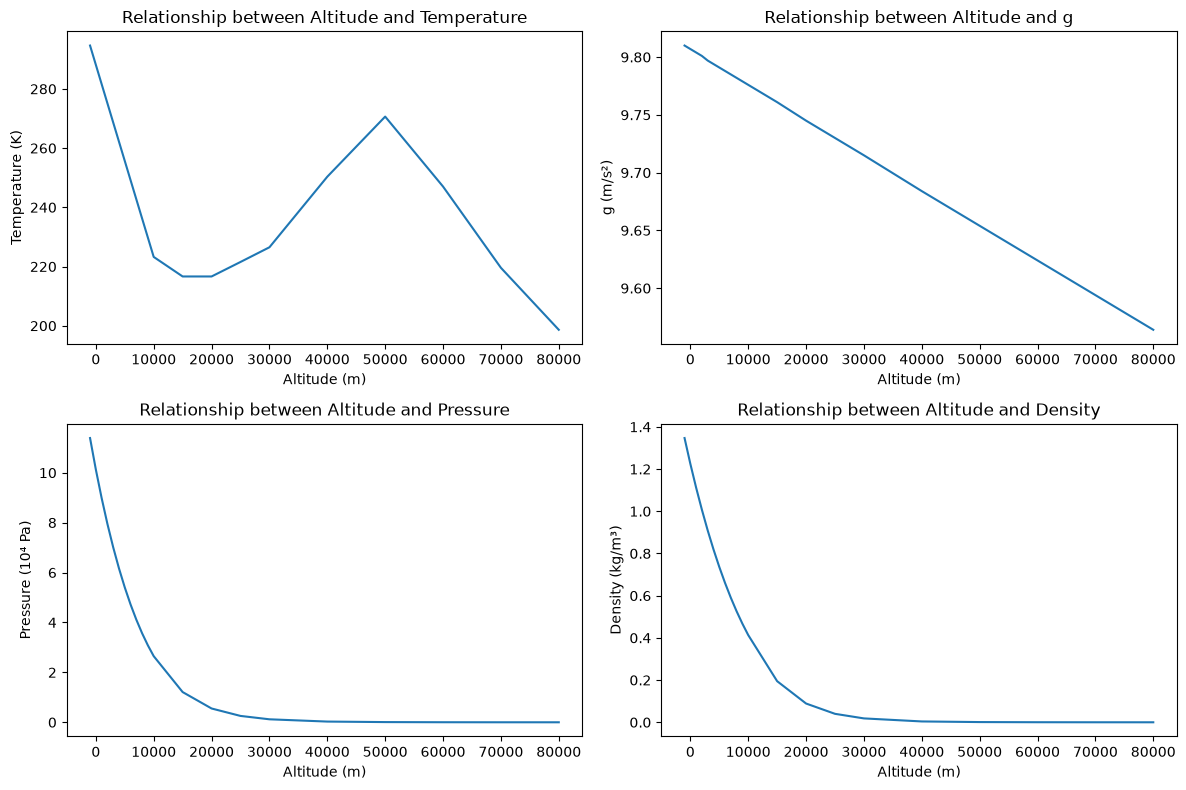

In [ ]:
# Plot relationships to altitude
import matplotlib.pyplot as plt

altitude = df['Altitude (m)']
dependent_vars = df.drop(columns=['Altitude (m)', 'Viscocity (10^-5 N*s/m²)'])  # Exclude altitude and viscosity for plotting

plt.figure(figsize=(12, 8))
for i, col in enumerate(dependent_vars.columns):
    plt.subplot(2, 2, i + 1)
    plt.plot(altitude, dependent_vars[col])
    plt.title(f"Relationship between Altitude and {col.split()[0]}")
    plt.xlabel('Altitude (m)')
    plt.ylabel(col)
plt.tight_layout()
plt.show()

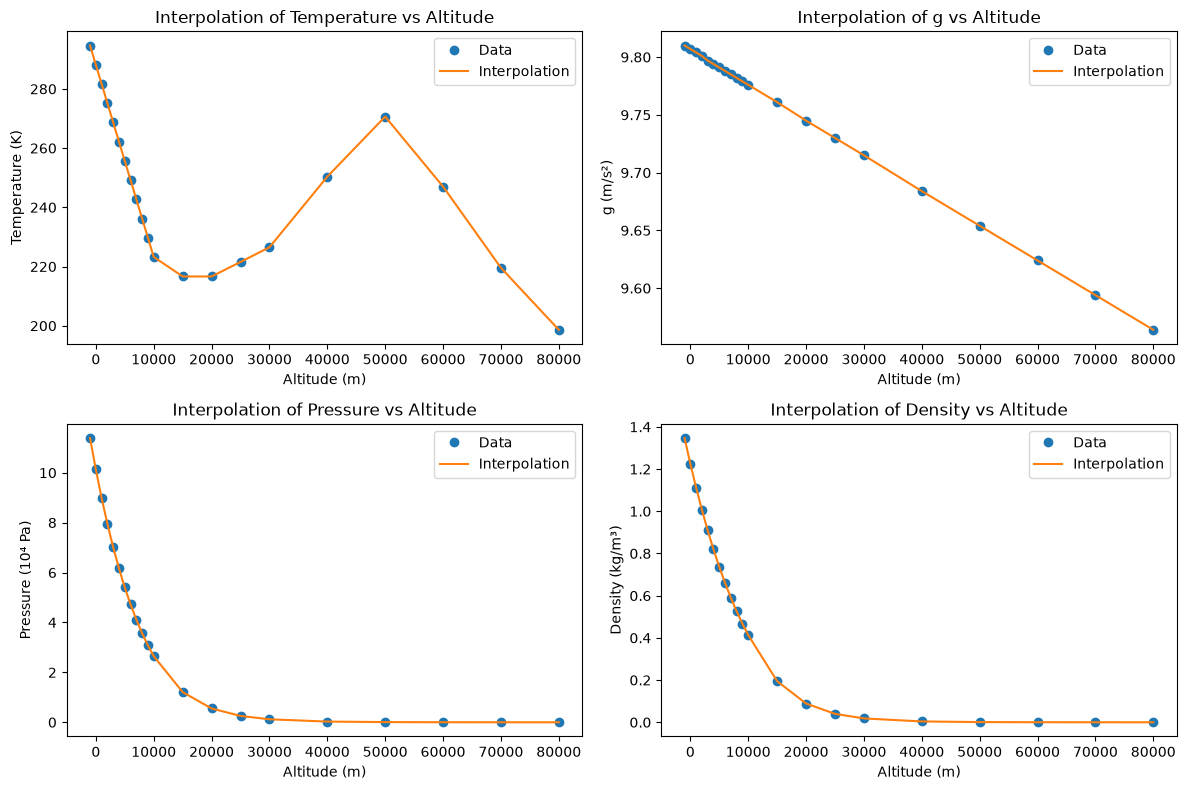

Evaluated values at specific altitudes:
       Temperature (K)  g (m/s²)  Pressure (10⁴ Pa)  Density (kg/m³)
0               288.15     9.807          10.130000         1.225000
1000            281.65     9.804           8.988000         1.112000
5000            255.68     9.791           5.405000         0.736400
10000           223.25     9.776           2.650000         0.413500
20000           216.65     9.745           0.552900         0.088910
30000           226.51     9.715           0.119700         0.018410
40000           250.35     9.684           0.028700         0.003996
50000           270.65     9.654           0.007978         0.001027


In [35]:
# Modeling relationships with altitude using interpolation
from scipy.interpolate import make_interp_spline

# Create interpolation functions for each dependent variable
interpolation_funcs = {}
for col in dependent_vars.columns:
    interpolation_funcs[col] = make_interp_spline(altitude, dependent_vars[col])

plt.figure(figsize=(12, 8))
for i, col in enumerate(dependent_vars.columns):
    plt.subplot(2, 2, i + 1)
    plt.plot(altitude, dependent_vars[col], 'o', label='Data')
    plt.plot(altitude, interpolation_funcs[col](altitude), '-', label='Interpolation')
    plt.title(f"Interpolation of {col.split()[0]} vs Altitude")
    plt.xlabel('Altitude (m)')
    plt.ylabel(col)
    plt.legend()
plt.tight_layout()
plt.show()

# Evaluate the interpolation functions at specific altitudes
specific_altitudes = [0, 1000, 5000, 10000, 20000, 30000, 40000, 50000]
evaluated_values = {col: interpolation_funcs[col](specific_altitudes) for col in dependent_vars.columns}
evaluated_df = pd.DataFrame(evaluated_values, index=specific_altitudes)
print("Evaluated values at specific altitudes:")
print(evaluated_df)

In [ ]:
import numpy as np
import scipy as sp
from scipy.integrate import solve_ivp

def c_func(y):
    # Interpolate the drag coefficient
    return interpolation_funcs['Density (kg/m³)'](y) 